# Задача 4. Энергетический отклик детектора

Используем модель из Задач 1–3 (классы `Detector` и `Source` из модулей `detector.py`, `source.py`): $R=2$ м, $N=40$, $r=10$ см, $a=0.5$, $Y=10\,000$ фотонов/МэВ.

**Что нужно:**
1. 1000 событий с $E=1$ МэВ в центре детектора — распределение полного собранного заряда $Q=\sum_i q_i$.
2. То же для $E=0.2,\,0.5,\,0.7,\,1.5,\,2.0,\,3.0$ МэВ — как зависит относительная ширина распределения от энергии.
3. То же для источника, смещённого на 1 м по оси $z$ — насколько меняется среднее значение заряда.

## Теоретические ожидания (чтобы было с чем сравнивать)

Пусть $f$ — доля телесного угла, занятая фотокатодами с точки расположения источника. Число фотонов $n\sim\mathrm{Pois}(YE)$; каждый фотон независимо попадает на фотокатод с вероятностью $f$ (прореживание пуассоновского потока даёт снова пуассоновский), поэтому число попавших $H\sim\mathrm{Pois}(\mu_H)$, $\mu_H=YEf$. Число фотоэлектронов при $H$ попаданиях $\sim\mathrm{Pois}(aH)$. Тогда
$$\langle Q\rangle=a\,\mu_H,\qquad \mathrm{Var}\,Q=a\mu_H+a^2\mu_H=a(1+a)\mu_H,$$
$$\boxed{\frac{\sigma_Q}{\langle Q\rangle}=\sqrt{\frac{1+a}{a\,Y\,E\,f}}\ \propto\ \frac{1}{\sqrt E}}$$
— обычная статистическая («пуассоновская») зависимость: относительная ширина определяется числом фотоэлектронов.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from detector import Detector
from source import Source

plt.rcParams['figure.figsize'] = (6, 3)
plt.rcParams['figure.autolayout'] = True

det = Detector(R=2.0, N=40, r=0.10, a=0.5, seed=1)
src = Source(Y=10_000, seed=2)
print(det, src)

N_EVENTS = 1000
ENERGIES = [0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]      # МэВ
CENTER = np.zeros(3)
SHIFTED = np.array([0.0, 0.0, 1.0])                  # смещение на 1 м по оси z

Detector(R=2.0 м, N=40, r=0.1 м, a=0.5; alpha=2.866°, покрытие=2.50%) Source(Y=10_000 фотонов/МэВ)


## Моделирование

`run_events` генерирует `n_events` независимых событий и возвращает полный заряд каждого и заряд по каналам.

In [2]:
def run_events(det, src, E, origin, n_events):
    """n_events событий с энергией E (МэВ) в точке origin.

    Возвращает (Q, charges): Q — (n_events,) полный заряд,
    charges — (n_events, N) заряд по каналам.
    """
    charges = np.empty((n_events, det.N), dtype=np.int64)
    for k in range(n_events):
        _, charges[k] = det.detect(origin, src.generate(E))
    return charges.sum(axis=1), charges


def run_scan(det, src, origin, energies, n_events):
    return {E: run_events(det, src, E, origin, n_events) for E in energies}

In [3]:
%%time
res_center = run_scan(det, src, CENTER, ENERGIES, N_EVENTS)
res_shift  = run_scan(det, src, SHIFTED, ENERGIES, N_EVENTS)

CPU times: user 1min 3s, sys: 124 ms, total: 1min 3s
Wall time: 1min 4s


## 1. 1000 событий по 1 МэВ в центре

E = 1 МэВ, центр, 1000 событий
  <Q>   = 124.67 ± 0.45   (теория 125.08)
  sigma = 14.32                  (теория 13.70)
  sigma/<Q> = 0.1148           (теория 0.1095)


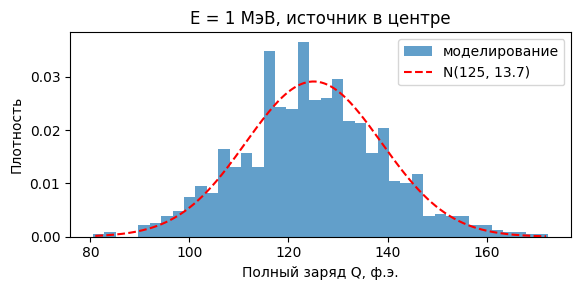

In [4]:
def theory_f(det):          # доля телесного угла в центре
    return det.coverage

def int_bins(x, max_bins=60):
    """Целочисленные корзины (заряд дискретен), но не более max_bins штук."""
    lo, hi = x.min(), x.max()
    if hi - lo + 2 <= max_bins:
        return np.arange(lo, hi + 2) - 0.5
    return np.linspace(lo - 0.5, hi + 0.5, max_bins + 1)

Q1 = res_center[1.0][0]
mu_H = src.Y * 1.0 * theory_f(det)
mean_th = det.a * mu_H
sig_th = np.sqrt(det.a * (1 + det.a) * mu_H)

print(f"E = 1 МэВ, центр, {N_EVENTS} событий")
print(f"  <Q>   = {Q1.mean():.2f} ± {Q1.std(ddof=1)/np.sqrt(N_EVENTS):.2f}   (теория {mean_th:.2f})")
print(f"  sigma = {Q1.std(ddof=1):.2f}                  (теория {sig_th:.2f})")
print(f"  sigma/<Q> = {Q1.std(ddof=1)/Q1.mean():.4f}           (теория {sig_th/mean_th:.4f})")

plt.hist(Q1, bins=int_bins(Q1, 40), density=True, alpha=0.7, label='моделирование')
x = np.linspace(Q1.min(), Q1.max(), 300)
plt.plot(x, np.exp(-0.5*((x-mean_th)/sig_th)**2)/(sig_th*np.sqrt(2*np.pi)), 'r--',
         label=f'N({mean_th:.0f}, {sig_th:.1f})')
plt.xlabel('Полный заряд Q, ф.э.'); plt.ylabel('Плотность'); plt.title('E = 1 МэВ, источник в центре')
plt.legend(); plt.show()

## 2. Зависимость от энергии (источник в центре)

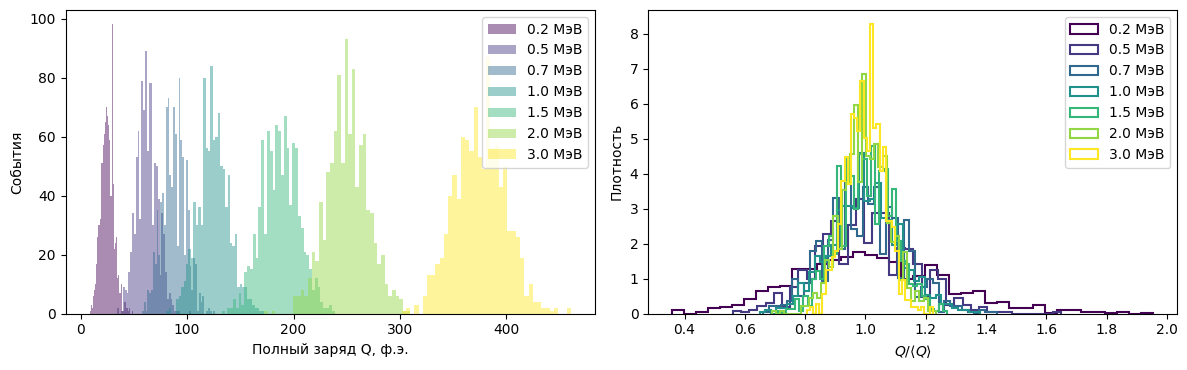

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
cmap = plt.get_cmap('viridis')
for k, E in enumerate(ENERGIES):
    Q = res_center[E][0]
    c = cmap(k / (len(ENERGIES) - 1))
    axs[0].hist(Q, bins=int_bins(Q, 40), density=False, histtype='stepfilled', alpha=0.45,
                color=c, label=f'{E} МэВ')
    axs[1].hist(Q / Q.mean(), bins=40, density=True, histtype='step', color=c, lw=1.5,
                label=f'{E} МэВ')
axs[0].set_xlabel('Полный заряд Q, ф.э.'); axs[0].set_ylabel('События'); axs[0].legend()
axs[1].set_xlabel(r'$Q/\langle Q\rangle$'); axs[1].set_ylabel('Плотность'); axs[1].legend()
plt.show()

In [6]:
f_c = theory_f(det)
E_arr = np.array(ENERGIES)
mean_c = np.array([res_center[E][0].mean() for E in ENERGIES])
std_c  = np.array([res_center[E][0].std(ddof=1) for E in ENERGIES])
rel_c  = std_c / mean_c
rel_err = rel_c / np.sqrt(2 * (N_EVENTS - 1))                 # ошибка выборочной sigma
rel_th = np.sqrt((1 + det.a) / (det.a * src.Y * E_arr * f_c))

print(f"{'E, МэВ':>7} {'<Q>':>9} {'теория':>9} {'sigma':>7} {'sigma/<Q>':>10} {'теория':>8}")
for E, m, s, r, rt in zip(E_arr, mean_c, std_c, rel_c, rel_th):
    print(f"{E:7.1f} {m:9.2f} {det.a*src.Y*E*f_c:9.2f} {s:7.2f} {r:10.4f} {rt:8.4f}")

 E, МэВ       <Q>    теория   sigma  sigma/<Q>   теория
    0.2     25.07     25.02    6.21     0.2476   0.2449
    0.5     62.48     62.54    9.52     0.1524   0.1549
    0.7     87.72     87.55   11.07     0.1262   0.1309
    1.0    124.67    125.08   14.32     0.1148   0.1095
    1.5    187.32    187.62   17.27     0.0922   0.0894
    2.0    250.54    250.16   19.36     0.0773   0.0774
    3.0    375.30    375.23   23.47     0.0625   0.0632


Фит: sigma/<Q> = 0.1099 * E^(-0.499)   (теория: показатель -0.5, k = 0.1095)


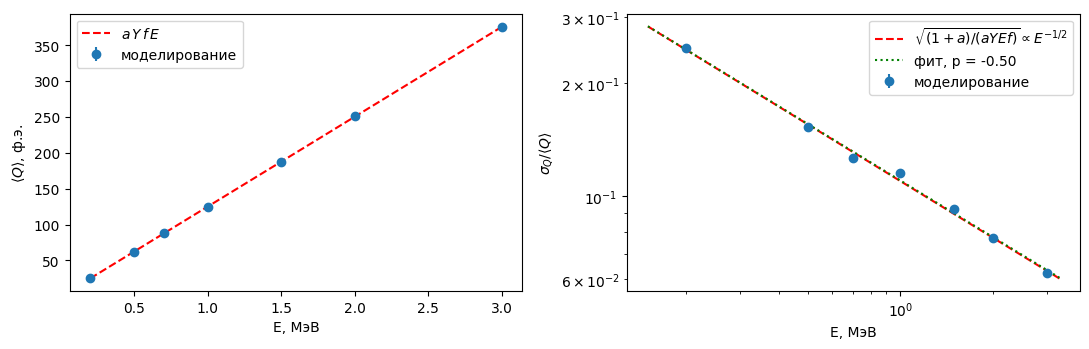

In [7]:
# степенная аппроксимация sigma/<Q> = k * E^p  в логарифмическом масштабе
w = 1 / (rel_err / rel_c)**2
p, logk = np.polyfit(np.log(E_arr), np.log(rel_c), 1, w=np.sqrt(w))
print(f"Фит: sigma/<Q> = {np.exp(logk):.4f} * E^({p:.3f})   (теория: показатель -0.5, "
      f"k = {np.sqrt((1+det.a)/(det.a*src.Y*f_c)):.4f})")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].errorbar(E_arr, mean_c, yerr=std_c/np.sqrt(N_EVENTS), fmt='o', label='моделирование')
axs[0].plot(E_arr, det.a*src.Y*f_c*E_arr, 'r--', label=r'$a\,Y\,f\,E$')
axs[0].set_xlabel('E, МэВ'); axs[0].set_ylabel(r'$\langle Q\rangle$, ф.э.'); axs[0].legend()

xx = np.linspace(0.15, 3.3, 100)
axs[1].errorbar(E_arr, rel_c, yerr=rel_err, fmt='o', label='моделирование')
axs[1].plot(xx, np.sqrt((1+det.a)/(det.a*src.Y*xx*f_c)), 'r--', label=r'$\sqrt{(1+a)/(aYEf)}\propto E^{-1/2}$')
axs[1].plot(xx, np.exp(logk) * xx**p, 'g:', label=f'фит, p = {p:.2f}')
axs[1].set_xscale('log'); axs[1].set_yscale('log')
axs[1].set_xlabel('E, МэВ'); axs[1].set_ylabel(r'$\sigma_Q/\langle Q\rangle$'); axs[1].legend()
plt.show()

## 3. Источник, смещённый на 1 м по оси $z$

E = 1 МэВ, z = +1 м:  <Q> = 124.75 ± 0.45,  sigma = 14.33,  sigma/<Q> = 0.1149
E = 1 МэВ, центр:     <Q> = 124.67 ± 0.45,  sigma = 14.32,  sigma/<Q> = 0.1148


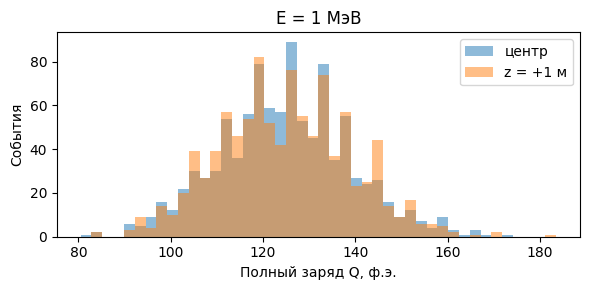

In [8]:
Q_s1 = res_shift[1.0][0]
print(f"E = 1 МэВ, z = +1 м:  <Q> = {Q_s1.mean():.2f} ± {Q_s1.std(ddof=1)/np.sqrt(N_EVENTS):.2f},"
      f"  sigma = {Q_s1.std(ddof=1):.2f},  sigma/<Q> = {Q_s1.std(ddof=1)/Q_s1.mean():.4f}")
print(f"E = 1 МэВ, центр:     <Q> = {Q1.mean():.2f} ± {Q1.std(ddof=1)/np.sqrt(N_EVENTS):.2f},"
      f"  sigma = {Q1.std(ddof=1):.2f},  sigma/<Q> = {Q1.std(ddof=1)/Q1.mean():.4f}")

b = np.linspace(min(Q1.min(), Q_s1.min()) - .5, max(Q1.max(), Q_s1.max()) + .5, 45)
plt.hist(Q1, bins=b, alpha=0.5, label='центр')
plt.hist(Q_s1, bins=b, alpha=0.5, label='z = +1 м')
plt.xlabel('Полный заряд Q, ф.э.'); plt.ylabel('События'); plt.title('E = 1 МэВ'); plt.legend(); plt.show()

Различие средних зарядов может быть мало по сравнению со статистической ошибкой 1000 событий, поэтому посчитаем **точное ожидаемое** изменение двумя независимыми способами:

* **Аналитически** (малые диски, $d\gg r$): телесный угол диска из точки $\vec o$ $\Omega_i\approx\pi r^2\cos\gamma_i/d_i^2$, где $d_i=|\vec c_i-\vec o|$, $\cos\gamma_i=\vec n_i\cdot(\vec c_i-\vec o)/d_i$; $f=\sum_i\Omega_i/4\pi$.
* **Монте-Карло с большой статистикой** — доля попаданий $10^7$ изотропных фотонов.

**Ожидание из закона Гаусса:** для *непрерывно* распределённых по сфере элементов площади $\sum \cos\gamma\,dA/d^2=4\pi$ из любой внутренней точки, т. е. покрытие не зависит от положения источника. У нас ФЭУ дискретны (40 штук), так что остаётся лишь небольшая «решёточная» вариация.

In [9]:
def f_analytic(det, origin):
    """Доля телесного угла ФЭУ из точки origin (малые диски)."""
    c = det.R * np.cos(det.alpha) * det.pmt_dirs                  # центры фотокатодов
    v = c - origin
    d = np.linalg.norm(v, axis=1)
    cosg = np.sum(det.pmt_dirs * v, axis=1) / d
    return np.sum(np.pi * det.r**2 * cosg / d**2) / (4 * np.pi)

def f_montecarlo(det, origin, n_total=10_000_000, chunk=200_000, seed=0):
    s = Source(seed=seed)
    hits = 0
    for _ in range(n_total // chunk):
        hits += np.count_nonzero(det.trace(origin, s.random_directions(chunk)) >= 0)
    f = hits / n_total
    return f, np.sqrt(f * (1 - f) / n_total)

rows = []
for name, o in [("центр", CENTER), ("z = +1 м", SHIFTED)]:
    fa = f_analytic(det, o)
    fm, fe = f_montecarlo(det, o)
    rows.append((name, fa, fm, fe))
    print(f"{name:9s}  f_аналит = {fa:.5f}   f_МК = {fm:.5f} ± {fe:.5f}   "
          f"<Q>(1 МэВ) = {det.a*src.Y*fm:.2f}")

dQ_th = (rows[1][2] / rows[0][2] - 1)
dQ_th_err = np.hypot(rows[0][3], rows[1][3]) / rows[0][2]
Qm_c, Qm_s = Q1.mean(), Q_s1.mean()
err = np.hypot(Q1.std(ddof=1), Q_s1.std(ddof=1)) / np.sqrt(N_EVENTS)
print(f"\nОжидаемое изменение среднего заряда (МК, 10^7 фотонов): {dQ_th:+.2%} ± {dQ_th_err:.2%}")
print(f"Аналитически (малые диски):                            {rows[1][1]/rows[0][1]-1:+.2%}")
print(f"Полученное в 1000 событий: {Qm_s - Qm_c:+.2f} ± {err:.2f} ф.э. = "
      f"{(Qm_s/Qm_c - 1):+.2%} ± {err/Qm_c:.2%}")

центр      f_аналит = 0.02506   f_МК = 0.02502 ± 0.00005   <Q>(1 МэВ) = 125.12


z = +1 м   f_аналит = 0.02504   f_МК = 0.02497 ± 0.00005   <Q>(1 МэВ) = 124.84

Ожидаемое изменение среднего заряда (МК, 10^7 фотонов): -0.22% ± 0.28%
Аналитически (малые диски):                            -0.10%
Полученное в 1000 событий: +0.09 ± 0.64 ф.э. = +0.07% ± 0.51%


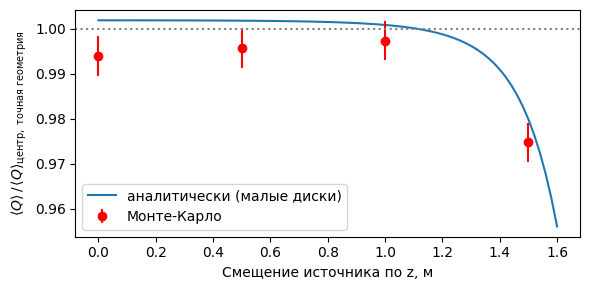

In [10]:
rho = np.linspace(0, 1.6, 81)
f_curve = np.array([f_analytic(det, np.array([0, 0, z])) for z in rho])

rho_pts = [0.0, 0.5, 1.0, 1.5]
mc = [f_montecarlo(det, np.array([0, 0, z]), n_total=2_000_000, seed=5) for z in rho_pts]

plt.plot(rho, f_curve / det.coverage, label='аналитически (малые диски)')
plt.errorbar(rho_pts, [m[0]/det.coverage for m in mc], yerr=[m[1]/det.coverage for m in mc],
             fmt='o', color='r', label='Монте-Карло')
plt.axhline(1, color='gray', ls=':')
plt.xlabel('Смещение источника по z, м'); plt.ylabel(r'$\langle Q\rangle\,/\,\langle Q\rangle_{\mathrm{центр,\ точная\ геометрия}}$')
plt.legend(); plt.show()

### Как меняется распределение по каналам

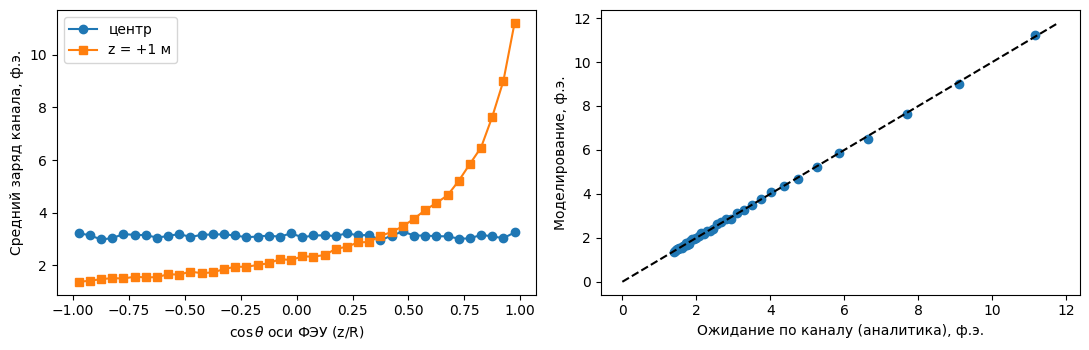

Заряд ближайшего к источнику канала: 11.2 ф.э. (в центре все ≈ 3.1)
Заряд самого далёкого канала:        1.36 ф.э.


In [11]:
mean_q_c = res_center[1.0][1].mean(axis=0)
mean_q_s = res_shift[1.0][1].mean(axis=0)
z_pmt = det.pmt_dirs[:, 2]                    # cos угла оси ФЭУ к оси z

order = np.argsort(z_pmt)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(z_pmt[order], mean_q_c[order], 'o-', label='центр')
axs[0].plot(z_pmt[order], mean_q_s[order], 's-', label='z = +1 м')
axs[0].set_xlabel(r'$\cos\theta$ оси ФЭУ (z/R)'); axs[0].set_ylabel('Средний заряд канала, ф.э.')
axs[0].legend()

# для сравнения: аналитика по каналам
def q_channel_analytic(det, origin, Y, E):
    c = det.R * np.cos(det.alpha) * det.pmt_dirs
    v = c - origin; d = np.linalg.norm(v, axis=1)
    cosg = np.sum(det.pmt_dirs * v, axis=1) / d
    return det.a * Y * E * (np.pi * det.r**2 * cosg / d**2) / (4 * np.pi)

axs[1].plot(q_channel_analytic(det, SHIFTED, src.Y, 1.0)[order], mean_q_s[order], 'o')
lim = [0, mean_q_s.max()*1.05]
axs[1].plot(lim, lim, 'k--')
axs[1].set_xlabel('Ожидание по каналу (аналитика), ф.э.'); axs[1].set_ylabel('Моделирование, ф.э.')
plt.show()

print(f"Заряд ближайшего к источнику канала: {mean_q_s.max():.1f} ф.э. (в центре все ≈ {mean_q_c.mean():.1f})")
print(f"Заряд самого далёкого канала:        {mean_q_s.min():.2f} ф.э.")

### Энергетическая шкала для смещённого источника

 E, МэВ  <Q> центр   <Q> z=1м   разн.  s/<Q> центр  s/<Q> z=1м  теория z=1м
    0.2      25.07      24.88  -0.72%       0.2476      0.2341       0.2451
    0.5      62.48      62.38  -0.15%       0.1524      0.1515       0.1550
    0.7      87.72      87.83  +0.13%       0.1262      0.1306       0.1310
    1.0     124.67     124.75  +0.07%       0.1148      0.1149       0.1096
    1.5     187.32     187.75  +0.23%       0.0922      0.0906       0.0895
    2.0     250.54     249.51  -0.41%       0.0773      0.0801       0.0775
    3.0     375.30     374.38  -0.24%       0.0625      0.0622       0.0633


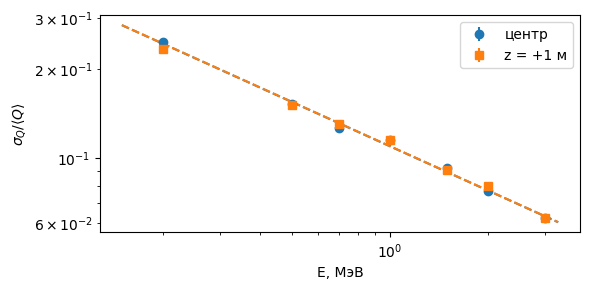

In [12]:
mean_s = np.array([res_shift[E][0].mean() for E in ENERGIES])
std_s  = np.array([res_shift[E][0].std(ddof=1) for E in ENERGIES])
rel_s  = std_s / mean_s
f_s_mc = rows[1][2]
rel_th_s = np.sqrt((1 + det.a) / (det.a * src.Y * E_arr * f_s_mc))

print(f"{'E, МэВ':>7} {'<Q> центр':>10} {'<Q> z=1м':>10} {'разн.':>7} {'s/<Q> центр':>12} {'s/<Q> z=1м':>11} {'теория z=1м':>12}")
for E, mc_, ms_, rc, rs, rt in zip(E_arr, mean_c, mean_s, rel_c, rel_s, rel_th_s):
    print(f"{E:7.1f} {mc_:10.2f} {ms_:10.2f} {(ms_/mc_-1):+7.2%} {rc:12.4f} {rs:11.4f} {rt:12.4f}")

plt.errorbar(E_arr, rel_c, yerr=rel_err, fmt='o', label='центр')
plt.errorbar(E_arr, rel_s, yerr=rel_s/np.sqrt(2*(N_EVENTS-1)), fmt='s', label='z = +1 м')
xx = np.linspace(0.15, 3.3, 100)
plt.plot(xx, np.sqrt((1+det.a)/(det.a*src.Y*xx*f_c)), 'C0--')
plt.plot(xx, np.sqrt((1+det.a)/(det.a*src.Y*xx*f_s_mc)), 'C1--')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('E, МэВ'); plt.ylabel(r'$\sigma_Q/\langle Q\rangle$'); plt.legend(); plt.show()

## Проверки согласия с теорией

In [13]:
def check(res, f, label):
    for E in ENERGIES:
        Q = res[E][0]
        mu_H = src.Y * E * f
        m_th, s_th = det.a * mu_H, np.sqrt(det.a * (1 + det.a) * mu_H)
        assert abs(Q.mean() - m_th) < 5 * s_th / np.sqrt(len(Q)), (label, E, Q.mean(), m_th)
        assert abs(Q.std(ddof=1) / s_th - 1) < 5 / np.sqrt(2 * (len(Q) - 1)), (label, E, Q.std(ddof=1), s_th)
    print("OK ", label)

check(res_center, rows[0][2], "центр: <Q> и sigma согласуются с теорией при всех E")
check(res_shift,  rows[1][2], "z = +1 м: <Q> и sigma согласуются с теорией при всех E")
assert abs(p + 0.5) < 0.05, p
print("OK  показатель степени sigma/<Q> ~ E^p:  p =", round(p, 3), "≈ -0.5")

OK  центр: <Q> и sigma согласуются с теорией при всех E
OK  z = +1 м: <Q> и sigma согласуются с теорией при всех E
OK  показатель степени sigma/<Q> ~ E^p:  p = -0.499 ≈ -0.5


## Выводы

* **Распределение заряда (1 МэВ, центр).** $\langle Q\rangle=124.7\pm0.5$ ф.э. при ожидаемых $125.1$; $\sigma=14.3$ (ожидание $13.7$). Форма близка к нормальной; ширина складывается из пуассоновских флуктуаций числа фотонов, числа попаданий на фотокатоды и числа фотоэлектронов: $\mathrm{Var}\,Q=a(1+a)\,\mu_H$ (множитель $1+a$ — вклад флуктуаций числа фотоэлектронов на попавший фотон сверх флуктуаций числа попаданий).
* **Зависимость от энергии.** Средний заряд строго линеен: $\langle Q\rangle\approx125\,E$ ф.э./МэВ. **Относительная ширина падает как $E^{-1/2}$**: $\sigma_Q/\langle Q\rangle$ уменьшается от $\approx0.25$ при 0.2 МэВ до $\approx0.06$ при 3 МэВ; степенная аппроксимация даёт показатель $-0.499$ (теория $-0.5$) и коэффициент $0.110$ (теория $0.1095$). Физически: относительная ширина определяется статистикой числа фотоэлектронов, которых на 1 МэВ всего $\approx125$. При 0.2 МэВ их всего $\approx25$, и распределение заметно дискретно и несимметрично.
* **Источник, смещённый на 1 м по $z$.** Среднее значение полного заряда **практически не меняется**: $124.75\pm0.45$ против $124.67\pm0.45$ ф.э. (разница в пределах статистической ошибки), аналитически и по Монте-Карло с $10^7$ фотонов ожидаемое изменение — менее $\sim0.3\%$ (и статистически неотличимо от нуля). Это следствие закона Гаусса: для (почти) равномерно распределённых по сфере элементов площади суммарный телесный угол из любой внутренней точки равен $4\pi$ — ближние ФЭУ видны под большим углом, дальние под меньшим, и в сумме это компенсируется. Остаётся лишь малая «решёточная» вариация из-за дискретности 40 ФЭУ. Ширина распределения при этом тоже не меняется.
* **Но распределение по каналам меняется сильно:** у ближайшего к источнику ФЭУ средний заряд $\approx11$ ф.э. против $\approx3.1$ при источнике в центре, у самого дальнего $\approx1.4$ ф.э. Именно эта асимметрия по каналам (а не полный заряд) несёт информацию о положении события и будет основой для реконструкции вершины. Полный заряд хорош как оценка энергии (слабо зависит от положения), но только до тех пор, пока источник не подходит близко к стенке (глубже $\sim r$ от ФЭУ приближение «малых дисков» перестаёт работать, и вариации растут).
